In [ ]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, models
from torchvision.datasets import ImageFolder

import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
from PIL import Image
from torch.cuda.amp import autocast, GradScaler

In [ ]:
import os
import kagglehub
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

kaggle_input = "/kaggle/input/chest-x-ray-6-classes-dataset"
if os.path.exists(kaggle_input):
    dataset_root = kaggle_input
else:
    dataset_root = kagglehub.dataset_download("mohamedasak/chest-x-ray-6-classes-dataset")
print("Dataset root:", dataset_root)

def find_folder(root, target):
    """Search recursively for a folder containing target (case-insensitive)."""
    for dirpath, dirnames, filenames in os.walk(root):
        for d in dirnames:
            if target.lower() in d.lower():
                return os.path.join(dirpath, d)
    return None

train_path = find_folder(dataset_root, "train")
val_path   = find_folder(dataset_root, "val")
test_path  = find_folder(dataset_root, "test")

if train_path is None or val_path is None or test_path is None:
    raise FileNotFoundError(f"Could not find train/val/test folders under {dataset_root}")

print("\nFound folders:")
print("Train:", train_path)
print("Val:  ", val_path)
print("Test: ", test_path)

#dataset structure
def print_tree(path, indent=0, max_depth=2):
    if indent > max_depth:
        return
    try:
        items = os.listdir(path)
    except PermissionError:
        return
    for item in items:
        full = os.path.join(path, item)
        if os.path.isdir(full):
            print("  " * indent + f"📁 {item}/")
            print_tree(full, indent+1, max_depth)
        else:
            print("  " * indent + f"📄 {item}")

print("\nFolder structure (first 2 levels):")
print_tree(dataset_root, max_depth=2)

100%|██████████| 194M/194M [00:11<00:00, 17.5MB/s]

Extracting files...


Dataset root: /root/.cache/kagglehub/datasets/mohamedasak/chest-x-ray-6-classes-dataset/versions/1

Found folders:
Train: /root/.cache/kagglehub/datasets/mohamedasak/chest-x-ray-6-classes-dataset/versions/1/chest-xray/train
Val:   /root/.cache/kagglehub/datasets/mohamedasak/chest-x-ray-6-classes-dataset/versions/1/chest-xray/val
Test:  /root/.cache/kagglehub/datasets/mohamedasak/chest-x-ray-6-classes-dataset/versions/1/chest-xray/test

Folder structure (first 2 levels):
📁 chest-xray/
  📁 val/
    📁 Pneumonia-Viral/
    📁 Pneumonia-Bacterial/
    📁 Emphysema/
    📁 Normal/
    📁 Tuberculosis/
    📁 Covid-19/
  📁 test/
    📁 Pneumonia-Viral/
    📁 Pneumonia-Bacterial/
    📁 Emphysema/
    📁 Normal/
    📁 Tuberculosis/
    📁 Covid-19/
  📁 train/
    📁 Pneumonia-Viral/
    📁 Pneumonia-Bacterial/
    📁 Emphysema/
    📁 Normal/
    📁 Tuberculosis/
    📁 Covid-19/


       Pneumonia-Viral  Pneumonia-Bacterial  Emphysema  Normal  Tuberculosis  \
Train             2413                 2400       2050    2671          2600   
Val                300                  300        250     300           298   
Test               300                  300        250     300           287   

       Covid-19  
Train      2417  
Val         300  
Test        300  


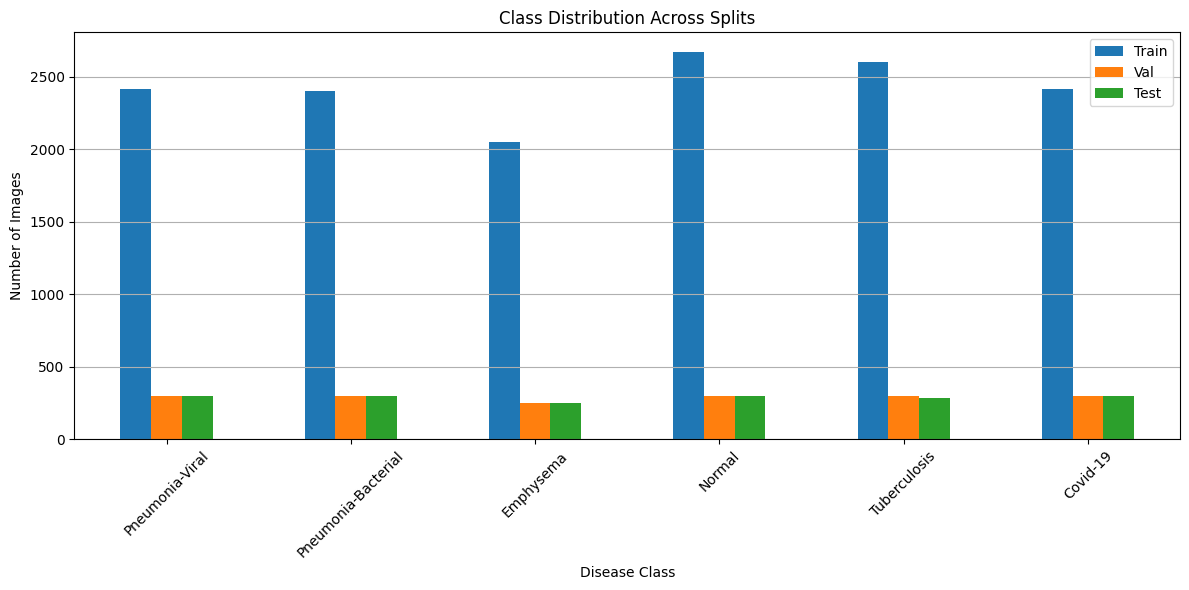

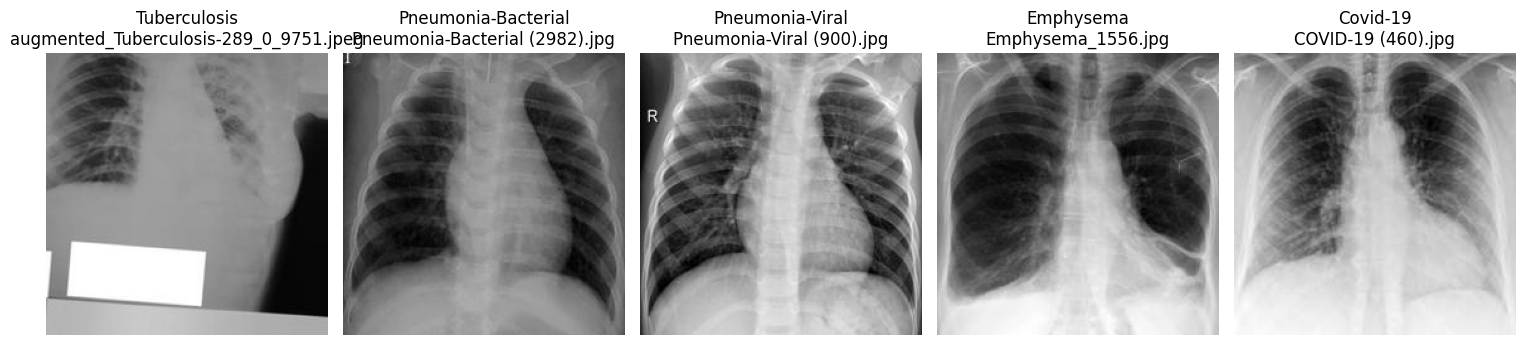

In [ ]:
def count_images(path):
    counts = {}
    for cls in os.listdir(path):
        cls_path = os.path.join(path, cls)
        if os.path.isdir(cls_path):
            counts[cls] = len(os.listdir(cls_path))
    return counts

train_counts = count_images(train_path)
val_counts   = count_images(val_path)
test_counts  = count_images(test_path)


df_counts = pd.DataFrame([train_counts, val_counts, test_counts],
                         index=["Train", "Val", "Test"]).fillna(0).astype(int)
print(df_counts)


df_counts.T.plot(kind='bar', figsize=(12,6))
plt.title("Class Distribution Across Splits")
plt.ylabel("Number of Images")
plt.xlabel("Disease Class")
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


def show_sample_images(path, num_samples=5):
    classes = os.listdir(path)
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))
    for i in range(num_samples):
        cls = random.choice(classes)
        cls_path = os.path.join(path, cls)
        img_name = random.choice(os.listdir(cls_path))
        img_path = os.path.join(cls_path, img_name)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(f"{cls}\n{img_name}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

show_sample_images(train_path, num_samples=5)

In [ ]:

CLASS_NAMES = ['Normal', 'Pneumonia-Bacterial', 'Pneumonia-Viral',
               'COVID-19', 'Tuberculosis', 'Emphysema']
num_classes = len(CLASS_NAMES)


train_transform = A.Compose([
    A.Resize(224, 224),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
    A.HorizontalFlip(p=0.5),
    A.Rotate(limit=10, p=0.5),
    A.CLAHE(p=0.5),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ToTensorV2(),
])


class ChestXrayDataset(Dataset):
    def __init__(self, folder_path, transform=None):
        self.folder_path = folder_path
        self.transform = transform
        self.classes = sorted(os.listdir(folder_path))
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}
        self.samples = []
        for cls in self.classes:
            cls_path = os.path.join(folder_path, cls)
            for img_name in os.listdir(cls_path):
                self.samples.append((os.path.join(cls_path, img_name), self.class_to_idx[cls]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)  # convert to 3-channel
        if self.transform:
            augmented = self.transform(image=img)
            img = augmented['image']
        return img, label


train_dataset = ChestXrayDataset(train_path, transform=train_transform)
val_dataset   = ChestXrayDataset(val_path,   transform=val_transform)
test_dataset  = ChestXrayDataset(test_path,  transform=val_transform)

batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(train_dataset)} images, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 14551 images, Val: 1748, Test: 1737


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [ ]:
class CBAM(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.channel_attention = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(channels, channels // reduction, 1),
            nn.ReLU(),
            nn.Conv2d(channels // reduction, channels, 1),
            nn.Sigmoid()
        )
        self.spatial_attention = nn.Sequential(
            nn.Conv2d(2, 1, kernel_size=7, padding=3),
            nn.Sigmoid()
        )

    def forward(self, x):
        ca = self.channel_attention(x) * x
        avg_out = torch.mean(ca, dim=1, keepdim=True)
        max_out, _ = torch.max(ca, dim=1, keepdim=True)
        spatial = torch.cat([avg_out, max_out], dim=1)
        sa = self.spatial_attention(spatial) * ca
        return sa

class DensNetCBAM(nn.Module):
    def __init__(self, num_classes, dropout_rate=0.5):
        super().__init__()
        base = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.features = base.features
        self.cbam = CBAM(channels=1024, reduction=16)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.cbam(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.classifier(x)
        return x


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = DensNetCBAM(num_classes=num_classes).to(device)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 190MB/s]


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-5)
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)
scaler = GradScaler()

epochs = 30
best_val_acc = 0.0
history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
    for images, labels in pbar:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        pbar.set_postfix({'loss': loss.item()})
    train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total


    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()
    val_loss /= len(val_loader)
    val_acc = 100. * correct_val / total_val


    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_acc'].append(train_acc)
    history['val_acc'].append(val_acc)


    print(f"Epoch {epoch+1}: Train Loss={train_loss:.2f}, Train Acc={train_acc:.2f}% | Val Loss={val_loss:.2f}, Val Acc={val_acc:.2f}%")


    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_model.pth")
        print(f"  ✓ New best model saved (Val Acc: {val_acc:.2f}%)")

    scheduler.step()

print("Training completed. Best validation accuracy: {:.2f}%".format(best_val_acc))

/tmp/ipykernel_457/3758622667.py:4: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
Epoch 1/30:   0%|          | 0/455 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_457/3758622667.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Epoch 1/30: 100%|██████████| 455/455 [01:30<00:00,  5.04it/s, loss=0.343]


Epoch 1: Train Loss=0.61, Train Acc=76.23% | Val Loss=0.33, Val Acc=86.16%
  ✓ New best model saved (Val Acc: 86.16%)


Epoch 2/30: 100%|██████████| 455/455 [01:23<00:00,  5.43it/s, loss=0.331]


Epoch 2: Train Loss=0.32, Train Acc=87.03% | Val Loss=0.28, Val Acc=88.90%
  ✓ New best model saved (Val Acc: 88.90%)


Epoch 3/30: 100%|██████████| 455/455 [01:22<00:00,  5.49it/s, loss=0.212]


...

Epoch 28: Train Loss=0.01, Train Acc=99.76% | Val Loss=0.24, Val Acc=95.25%
  ✓ New best model saved (Val Acc: 95.25%)


Epoch 29/30: 100%|██████████| 455/455 [01:21<00:00,  5.55it/s, loss=0.000899]


Epoch 29: Train Loss=0.01, Train Acc=99.79% | Val Loss=0.24, Val Acc=94.97%


Epoch 30/30: 100%|██████████| 455/455 [01:22<00:00,  5.51it/s, loss=0.0176]


Epoch 30: Train Loss=0.01, Train Acc=99.85% | Val Loss=0.24, Val Acc=94.85%
Training completed. Best validation accuracy: 95.25%


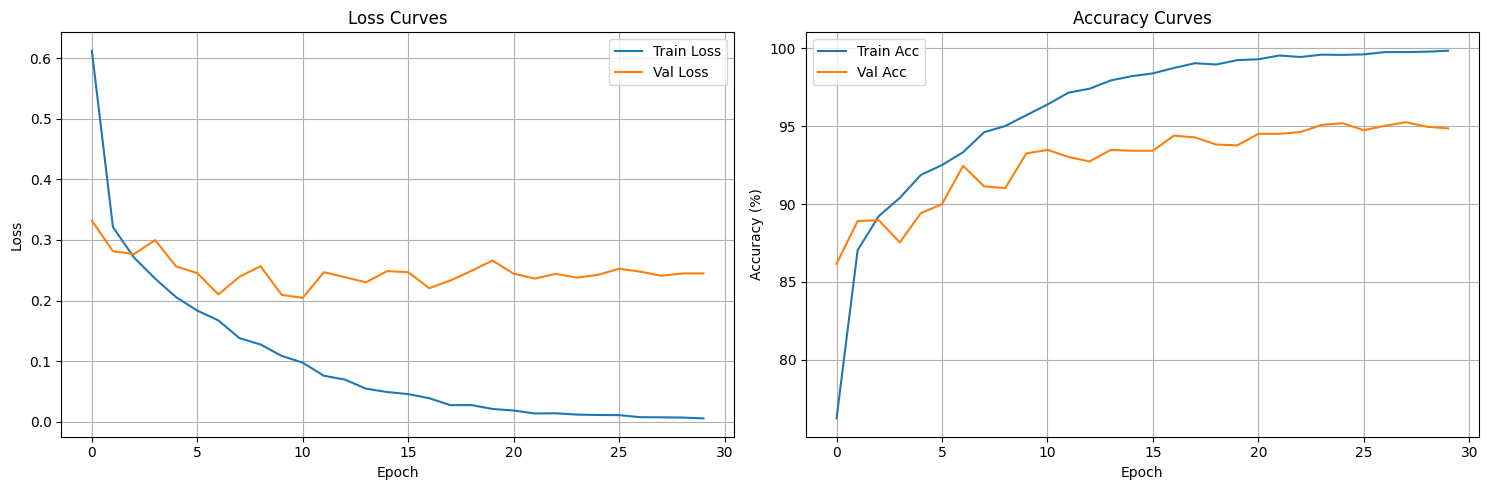

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.plot(history['train_loss'], label='Train Loss')
ax1.plot(history['val_loss'], label='Val Loss')
ax1.set_title('Loss Curves')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(history['train_acc'], label='Train Acc')
ax2.plot(history['val_acc'], label='Val Acc')
ax2.set_title('Accuracy Curves')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files
files.download("best_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

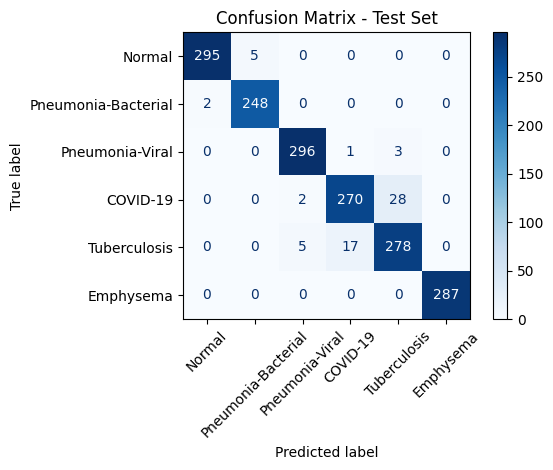

Classification Report on Test Set:
                     precision    recall  f1-score   support

             Normal       0.99      0.98      0.99       300
Pneumonia-Bacterial       0.98      0.99      0.99       250
    Pneumonia-Viral       0.98      0.99      0.98       300
           COVID-19       0.94      0.90      0.92       300
       Tuberculosis       0.90      0.93      0.91       300
          Emphysema       1.00      1.00      1.00       287

           accuracy                           0.96      1737
          macro avg       0.96      0.96      0.96      1737
       weighted avg       0.96      0.96      0.96      1737



In [ ]:
model.load_state_dict(torch.load("best_model.pth"))
model.eval()


all_preds = []
all_labels = []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())


cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix - Test Set")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


print("Classification Report on Test Set:")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

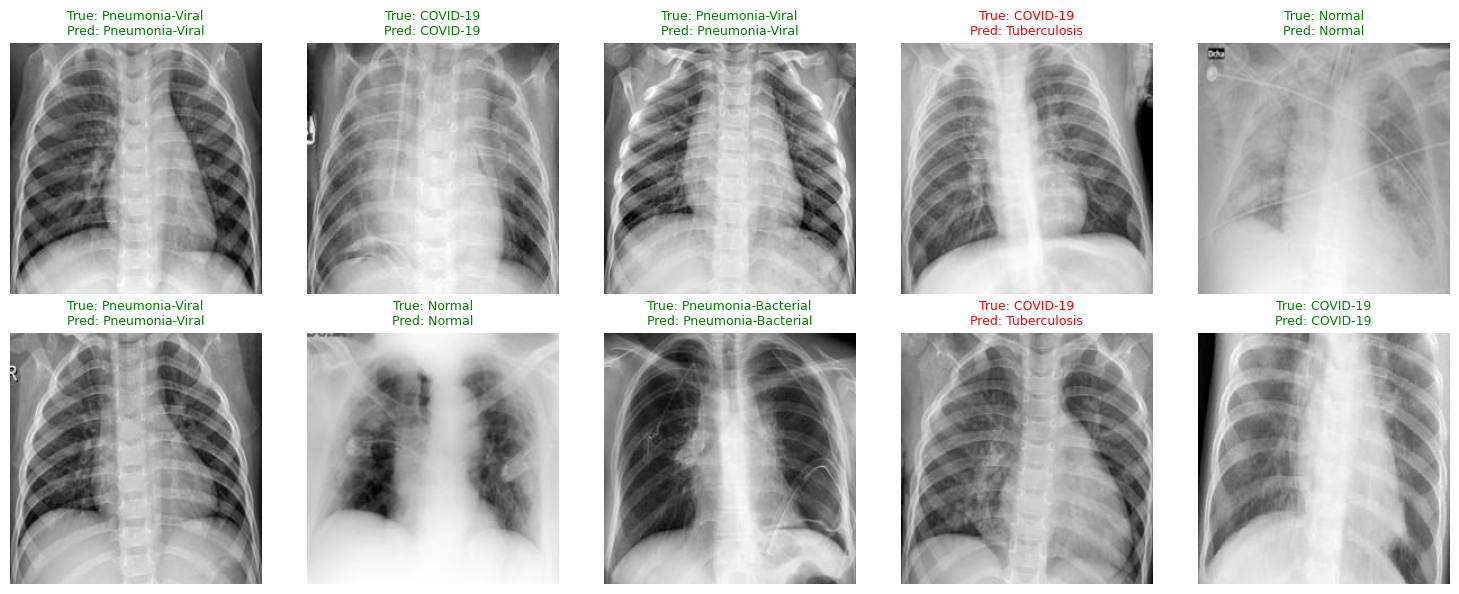

In [ ]:
def show_random_predictions(model, dataset, class_names, num_images=10):
    model.eval()
    device = next(model.parameters()).device
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.flatten()
    indices = random.sample(range(len(dataset)), num_images)
    for i, idx in enumerate(indices):
        img, true_label = dataset[idx]
        img_path, _ = dataset.samples[idx]
        orig_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        axes[i].imshow(orig_img, cmap='gray')

        img_tensor = img.unsqueeze(0).to(device)
        with torch.no_grad():
            output = model(img_tensor)
            _, pred = output.max(1)
        true_name = class_names[true_label]
        pred_name = class_names[pred.item()]
        color = 'green' if true_label == pred.item() else 'red'
        axes[i].set_title(f"True: {true_name}\nPred: {pred_name}", color=color, fontsize=9)
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

show_random_predictions(model, test_dataset, CLASS_NAMES, num_images=10)